In [3]:
import pandas as pd

from presyo_ph.ml import (
    ForecastConfig,
    prepare_time_series,
    generate_forecasts,
    evaluate_forecasts,
    walk_forward_evaluate,
)

from presyo_ph.medallion.gold import load_gold_table
from presyo_ph.spark import get_spark_session

In [7]:
spark = get_spark_session()
gold_df = load_gold_table(spark, "national_monthly_prices")
rice_df = (
    gold_df
    .filter("commodity = 'rice'")
    .select("price_date", "avg_price")
    .toPandas()
)

rice_df

Gold table loaded: national_monthly_prices (local)


,price_date,avg_price
0,2007-01-01,21.402857
1,2007-02-01,21.645714
2,2007-03-01,22.217143
3,2007-04-01,22.410714
4,2007-05-01,22.712857
...,...,...
220,2025-05-01,42.893494
221,2025-06-01,42.061084
222,2025-07-01,40.849518
223,2025-08-01,39.862289


In [8]:
config = ForecastConfig(
    date_col="price_date",
    target_col="avg_price",
    horizon=12,
    test_size=12,
)

rice_series = prepare_time_series(
    rice_df,
    date_col=config.date_col,
    target_col=config.target_col,
)

In [9]:
display(rice_series.to_frame())

,avg_price
price_date,
2007-01-01,21.402857
2007-02-01,21.645714
2007-03-01,22.217143
2007-04-01,22.410714
2007-05-01,22.712857
...,...
2025-05-01,42.893494
2025-06-01,42.061084
2025-07-01,40.849518


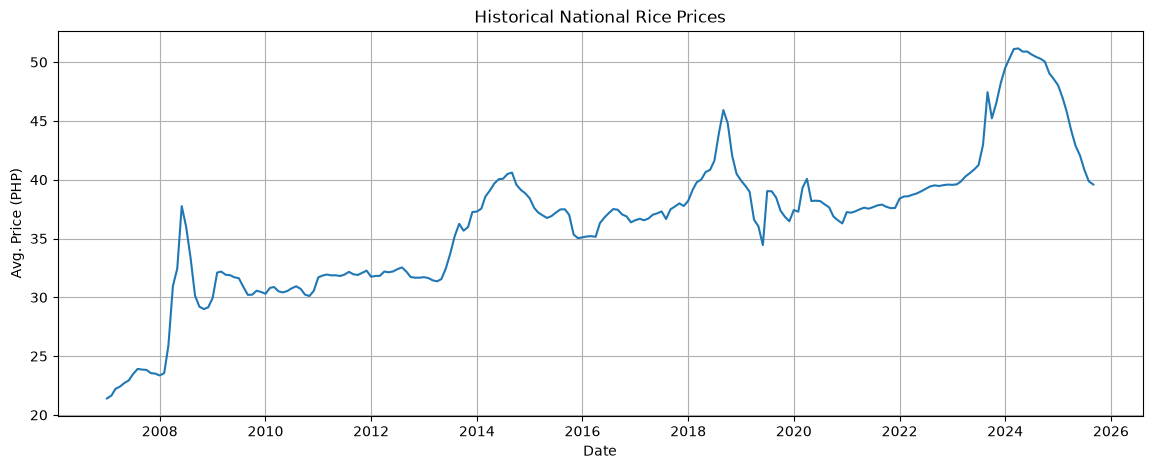

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    rice_series.index,
    rice_series.values,
)

plt.title("Historical National Rice Prices")
plt.xlabel("Date")
plt.ylabel("Avg. Price (PHP)")
plt.grid(True)
plt.show()

In [11]:
results = walk_forward_evaluate(
    rice_series,
    config,
    n_splits=3,
)

display(results)

,model,mae,rmse,smape
0,sarima,3.030486,4.025795,6.499116
1,holt_winters,3.152175,3.987248,6.798376
2,naive,3.183223,3.996030,6.881460
3,random_forest,4.269226,5.143503,9.297761
4,moving_average,4.290459,5.120394,9.309302
5,xgboost,5.101687,5.945237,11.315803
6,seasonal_naive,5.688711,6.308489,12.659844


In [12]:
forecasts = generate_forecasts(
    rice_series,
    horizon=config.horizon,
    config=config,
)

In [13]:
forecast_df = pd.DataFrame(forecasts)

display(forecast_df)

,naive,seasonal_naive,moving_average,sarima,holt_winters,random_forest,xgboost
2025-10-01,39.591325,50.044217,40.101044,37.790162,39.041050,39.277329,38.807201
2025-11-01,39.591325,49.040482,40.101044,37.717355,38.751617,39.248340,37.625973
2025-12-01,39.591325,48.569277,40.101044,38.085705,38.734253,39.336728,36.939682
2026-01-01,39.591325,48.021205,40.101044,38.586095,38.976831,39.415981,36.876968
2026-02-01,39.591325,46.956988,40.101044,38.723130,39.142142,39.460092,37.211388
2026-03-01,39.591325,45.792530,40.101044,38.922700,39.440358,39.527038,37.504395
2026-04-01,39.591325,44.206627,40.101044,38.763294,39.596997,39.694782,37.791271
2026-05-01,39.591325,42.893494,40.101044,38.451741,39.639203,39.953681,38.040314
2026-06-01,39.591325,42.061084,40.101044,38.372633,39.941040,40.134493,37.962093
2026-07-01,39.591325,40.849518,40.101044,38.246746,40.256934,40.509481,37.943218


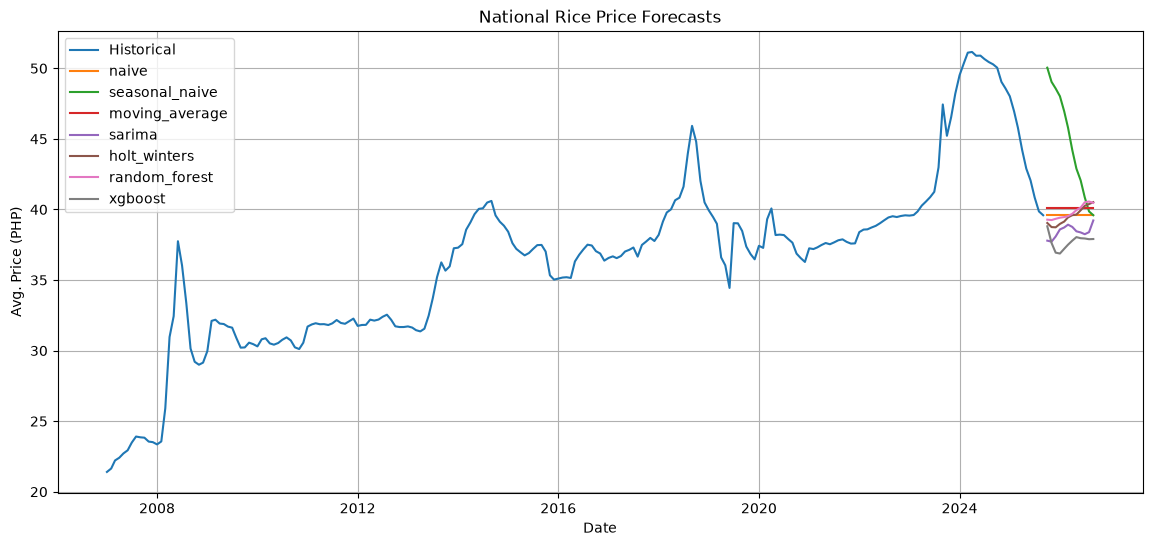

In [16]:
plt.figure(figsize=(14, 6))

plt.plot(
    rice_series.index,
    rice_series.values,
    label="Historical",
)

for model_name, predictions in forecasts.items():
    plt.plot(
        predictions.index,
        predictions.values,
        label=model_name,
    )

plt.title("National Rice Price Forecasts")
plt.xlabel("Date")
plt.ylabel("Avg. Price (PHP)")
plt.legend()
plt.grid(True)
plt.show()